# CSE 4554 – Machine Learning Lab
## Experiment No. 2: Visualization, Preprocessing, and Linear Regression Modeling of a Dataset

**Instructions**

1. Complete every code cell that contains a `TODO` marker. Do not rename the variables; later tasks depend on them.
2. After each task, run its verification cell. Verification cells must not be modified.
3. Answer each question in the *Answer* line of the cell below it.
4. Task 8 must be completed independently.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---- Verification helper (do not modify) ----
def check(label, test):
    """Runs test() and reports PASS, FAIL or PENDING (a preceding cell is not completed yet)."""
    try:
        ok = bool(test())
    except Exception as e:
        print(f"[PENDING] {label} (complete the preceding cells first: {type(e).__name__})")
        return
    print(("[PASS]    " if ok else "[FAIL]    ") + label)

---
# Part A: Data
## Task 1: Load the Dataset

**Objective.** Generate the synthetic house price dataset, save it as a `.csv` file (with header) and as a `.txt` file (tab-separated, no header), and load the `.txt` file.

**Notes**
- The code is provided. Run it and read each line.
- The `.txt` file has no header row; the column names are supplied through the `names` argument of `read_csv`.

**Checkpoint.** `df` has three named columns and `df.shape` is `(200, 3)`.

In [15]:
np.random.seed(42)
n_samples = 200
size = np.clip(np.random.normal(2000, 700, n_samples), 300, None)   # no tiny or negative sizes
bedrooms = np.random.randint(1, 6, n_samples)
price = size * 0.15 + bedrooms * 30 + np.random.normal(0, 50, n_samples) + 100

data = pd.DataFrame({'HouseSize': size, 'Bedrooms': bedrooms, 'Price': price})
data.to_csv('house_price_data.csv', index=False)
data.to_csv('house_price_data.txt', sep='\t', index=False, header=False)

# Load without header
df = pd.read_csv('house_price_data.txt', sep='\t', header=None,
                 names=['HouseSize', 'Bedrooms', 'Price'])
print(df.head())

     HouseSize  Bedrooms       Price
0  2347.699907         2  572.401132
1  1903.214989         2  385.649225
2  2453.381977         1  536.541213
3  3066.120899         1  623.270940
4  1836.092638         1  370.456567


In [16]:
# Verification. Do not modify this cell.
check("shape is (200, 3)", lambda: df.shape == (200, 3))
check("columns are HouseSize, Bedrooms, Price", lambda: list(df.columns) == ['HouseSize', 'Bedrooms', 'Price'])

[PASS]    shape is (200, 3)
[PASS]    columns are HouseSize, Bedrooms, Price


## Task 2: Visualize Each Feature Against Price

**Objective.** Create three scatter plots side by side: `HouseSize` vs `Price`, `Bedrooms` vs `Price`, and `HouseSize` vs `Price` colored by `Bedrooms`.

**Notes**
- `plt.subplots(1, 3, ...)` returns a figure and an array of three axes.
- Panel 1 is provided as a reference. Panels 2 and 3 follow the same pattern.
- A color scale for panel 3 is created with the `c` argument of `scatter` and a color bar.

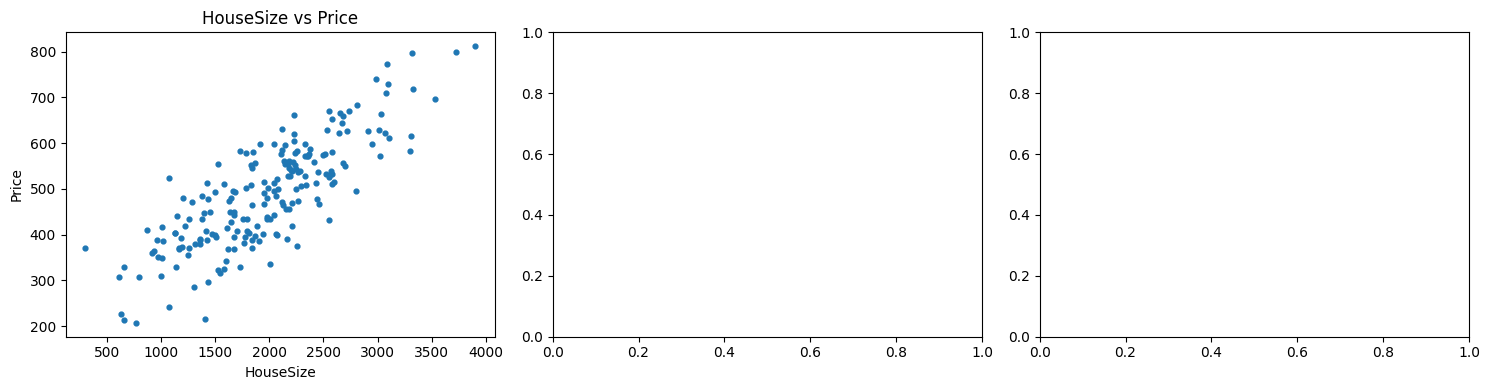

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Panel 1 (provided as a reference)
axes[0].scatter(df['HouseSize'], df['Price'], s=12)
axes[0].set_title('HouseSize vs Price')
axes[0].set_xlabel('HouseSize')
axes[0].set_ylabel('Price')

# TODO: Panel 2 - Bedrooms vs Price


# TODO: Panel 3 - HouseSize vs Price, colored by Bedrooms (include a color bar)


plt.tight_layout()
plt.show()

In [ ]:
# Verification. Do not modify this cell.
check("all three panels contain points", lambda: all(len(a.collections) > 0 for a in axes))

**Question.** Which feature appears to be more strongly related to `Price`? What does the third plot show that the first two do not?

**Answer:**

## Task 3: Statistical Summary

**Objective.** Compute the mean, median, standard deviation, and variance of the input features `HouseSize` and `Bedrooms`.

**Notes**
- The DataFrame method `agg` accepts a list of statistic names.

In [ ]:
stats = None  # TODO
stats

In [ ]:
# Verification. Do not modify this cell.
check("stats contains the HouseSize mean (about 1972)",
      lambda: (abs(np.asarray(stats, dtype=float) - 1972.13) < 0.5).any())

**Question.** Compare the standard deviations of the two features. Why can a large difference in scale be a problem for gradient descent?

**Answer:**

## Task 4: Split the Dataset

**Objective.** Split the data into 80% training and 20% testing sets, before any normalization.

**Notes**
- `train_test_split` returns four arrays in the order `X_train, X_test, y_train, y_test`.
- Use `test_size=0.2` and `random_state=42`.

**Checkpoint.** The shapes are `(160, 2)`, `(40, 2)`, `(160,)` and `(40,)`.

In [ ]:
X = df[['HouseSize', 'Bedrooms']].values
y = df['Price'].values

# TODO: split into training and test sets
X_train, X_test, y_train, y_test = None, None, None, None

In [ ]:
# Verification. Do not modify this cell.
check("X_train (160, 2) and X_test (40, 2)", lambda: X_train.shape == (160, 2) and X_test.shape == (40, 2))
check("y_train (160,) and y_test (40,)", lambda: y_train.shape == (160,) and y_test.shape == (40,))

---
# Part B: Preprocessing
## Task 5: Z-score Normalization

**Objective.** Normalize the features using $z = \dfrac{x - \mu}{\sigma}$.

**Notes**
- Compute the mean and standard deviation per column.
- Both statistics are computed from `X_train` only and are then applied to `X_test`.
- The function accepts optional `mean` and `std` arguments. When they are provided, they are used instead of being recomputed.

**Checkpoint.** Each column of the normalized `X_train` has mean approximately 0 and standard deviation approximately 1. The normalized `X_test` is close to these values but not exactly equal.

In [ ]:
def z_score_normalize(X, mean=None, std=None):
    """Return (X_normalized, mean, std). Compute mean/std from X only if they are not given."""
    # TODO
    raise NotImplementedError("finish z_score_normalize")


# TODO: normalize the training set (this computes mu and sigma)
X_train_norm, mu, sigma = None, None, None

# TODO: normalize the test set using the training mu and sigma
X_test_norm = None

In [ ]:
# Verification. Do not modify this cell.
check("train mean is about 0", lambda: np.allclose(X_train_norm.mean(axis=0), 0, atol=1e-8))
check("train std is about 1", lambda: np.allclose(X_train_norm.std(axis=0), 1, atol=1e-8))
check("test set is close to, but not exactly, 0 / 1 (training statistics used)",
      lambda: (np.abs(X_test_norm.mean(axis=0)) > 1e-6).all() and np.abs(X_test_norm.mean(axis=0)).max() < 0.5)

**Question.** Why must the test set not be used to compute the mean and standard deviation?

**Answer:**

## Task 6: Add the Bias Term

**Objective.** Add a column of ones to the normalized `X_train` and `X_test`, and define the hypothesis function $h_\theta(X) = X\theta$.

**Notes**
- Store the results in new variables (`X_train_b`, `X_test_b`). The matrices without the bias column are required in Task 12.

**Checkpoint.** `X_train_b` has shape `(160, 3)` and its first column consists of ones.

In [ ]:
# TODO: matrices with a leading column of ones
X_train_b = None
X_test_b = None


def hypothesis(X, theta):
    # TODO
    pass

In [ ]:
# Verification. Do not modify this cell.
check("X_train_b is (160, 3), X_test_b is (40, 3)", lambda: X_train_b.shape == (160, 3) and X_test_b.shape == (40, 3))
check("first column is all ones", lambda: np.all(X_train_b[:, 0] == 1) and np.all(X_test_b[:, 0] == 1))
check("X_train_norm still has only 2 columns", lambda: X_train_norm.shape == (160, 2))
check("hypothesis(X, theta) returns shape (160, 1)", lambda: hypothesis(X_train_b, np.zeros((3, 1))).shape == (160, 1))

---
# Part C: Gradient Descent
## Task 7: Cost Function

**Objective.** Implement $J(\theta) = \dfrac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x^{(i)}) - y^{(i)}\right)^2$.

**Notes**
- The implementation is provided. Review each line before proceeding.
- `y.reshape(-1, 1)` makes the shape of `y` match the shape of `predictions`.

**Checkpoint.** With `theta = np.zeros((3, 1))` the cost is approximately $1.3 \times 10^5$.

In [ ]:
def cost_function(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    error = predictions - y.reshape(-1, 1)
    return (1/(2*m)) * np.sum(error**2)


print(cost_function(X_train_b, y_train, np.zeros((3, 1))))

In [ ]:
# Verification. Do not modify this cell.
check("cost with theta = 0 is about 1.3e5", lambda: 1.2e5 < cost_function(X_train_b, y_train, np.zeros((3, 1))) < 1.3e5)

## Task 8: Implement Gradient Descent

**Objective.** Complete the body of the loop using the update rule given in Section 3.3 of the manual.

**Notes**
- Expected shapes inside the loop:

| Variable | Shape |
|---|---|
| `predictions` | `(m, 1)` |
| `error` | `(m, 1)` |
| `gradient` | `(n+1, 1)`, the same as `theta` |
| updated `theta` | `(n+1, 1)` |

- All parameters are updated simultaneously.

**Checkpoint.** The cost at epoch 0 is approximately $10^5$ and decreases quickly. The returned `theta` has shape `(3, 1)`.

In [ ]:
def gradient_descent(X, y, theta, learning_rate=0.1, num_epochs=200):
    """Perform gradient descent to learn theta. Returns the final theta and the list of costs."""
    m = len(y)
    J_history = []
    y = y.reshape(-1, 1)

    for epoch in range(num_epochs):
        # ---- YOUR CODE STARTS HERE (about 4 lines) ----
        # 1. Compute predictions
        # 2. Compute error
        # 3. Compute gradient
        # 4. Update theta simultaneously

        # ---- YOUR CODE ENDS HERE ----

        cost = cost_function(X, y, theta)
        J_history.append(cost)

        if epoch % 20 == 0:
            print(f"Epoch {epoch:3d} | Cost: {cost:.4f}")

    return theta, J_history

In [ ]:
# Verification. Do not modify this cell.: runs 100 quiet epochs from theta = 0
import io, contextlib

def _quiet_gd():
    with contextlib.redirect_stdout(io.StringIO()):
        return gradient_descent(X_train_b, y_train, np.zeros((3, 1)), 0.1, 100)

check("returned theta has shape (3, 1)", lambda: _quiet_gd()[0].shape == (3, 1))
check("cost never increases (decreases, then flattens)", lambda: np.all(np.diff(_quiet_gd()[1]) <= 1e-9) and _quiet_gd()[1][0] > 10 * _quiet_gd()[1][-1])
check("final cost is about 1.3e3", lambda: 1200 < _quiet_gd()[1][-1] < 1400)

## Task 9: Run Gradient Descent

**Objective.** Train the model on the normalized training data with the bias column, using learning rate 0.1 and 200 epochs, and print the final parameters.

**Notes**
- Initialize `theta_init` with small random values of shape `(3, 1)`.
- Keep `theta_init`; Task 11 uses the same starting point.

**Checkpoint.** The cost settles at approximately $1.3 \times 10^3$ after roughly 100 epochs.

In [ ]:
np.random.seed(0)
theta_init = None  # TODO: small random values, shape (3, 1)

theta, J_history = None, None  # TODO: run gradient descent
print("theta:", theta.ravel())

In [ ]:
# Verification. Do not modify this cell.
check("theta has shape (3, 1)", lambda: theta.shape == (3, 1))
check("final cost is about 1.3e3", lambda: 1200 < J_history[-1] < 1400)

**Question.** What does the parameter $\theta_1$ represent? (The features are normalized, so its unit is one standard deviation of `HouseSize`.)

**Answer:**

## Task 10: Plot the Best-fit Line

**Objective.** Plot the regression line of `Price` against `HouseSize` with `Bedrooms` fixed at its average value, together with the training data. The horizontal axis must use the original units.

**Notes**
- Follow the numbered steps in the code cell.
- The model expects normalized inputs, computed with the training statistics (`mu`, `sigma`).

**Checkpoint.** The horizontal axis shows house sizes in the hundreds and thousands.

In [ ]:
# 1. About 100 evenly spaced sizes (original units) between the smallest and largest in X_train
sizes = None  # TODO

# 2. Normalize the sizes using the training mean and standard deviation of HouseSize
sizes_norm = None  # TODO

# 3. Bedrooms at its average value, expressed in normalized units
bedrooms_norm = None  # TODO

# 4. Predicted prices
line = None  # TODO

# 5. Plot the training data and the line (x-axis in original units)
plt.figure(figsize=(7, 4))
# TODO: scatter plot of the training data
# TODO: line plot of the predictions
plt.xlabel('HouseSize')
plt.ylabel('Price')
plt.legend()
plt.show()

In [ ]:
# Verification. Do not modify this cell.
check("sizes are in original units", lambda: np.max(sizes) > 1000)
check("line has one prediction per size", lambda: np.asarray(line).size == np.asarray(sizes).size > 1)

## Task 11: Compare Learning Rates

**Objective.** Run gradient descent with learning rates 0.001, 0.1 and 2.5, and plot the three cost curves in a single figure.

**Notes**
- Every run starts from the same `theta_init`.
- Store each cost history in the `histories` dictionary, which is used by the verification cell.
- Use a logarithmic vertical axis. Overflow warnings for the largest learning rate are expected.

**Checkpoint.** For learning rate 2.5 the cost increases at every epoch. For the other two it decreases.

In [ ]:
learning_rates = [0.001, 0.1, 2.5]
histories = {}

for lr in learning_rates:
    # TODO: run gradient descent from theta_init and store the cost history in histories[lr]
    pass

plt.figure(figsize=(7, 4))
# TODO: plot one labeled curve per learning rate
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('Cost J(theta)')
plt.legend()
plt.show()

In [ ]:
# Verification. Do not modify this cell.
check("alpha = 0.001: cost decreases every epoch", lambda: np.all(np.diff(histories[0.001]) < 0))
check("alpha = 0.1: cost decreases, then flattens", lambda: np.all(np.diff(histories[0.1]) <= 1e-9) and histories[0.1][0] > 10 * histories[0.1][-1])
check("alpha = 2.5: cost increases every epoch", lambda: np.all(np.diff(np.array(histories[2.5], dtype=float)[:20]) > 0))

**Question.** Describe the behavior of each cost curve and explain the cause in terms of step size.

**Answer:**

---
# Part D: Validation of Results
## Task 12: Compare with scikit-learn

**Objective.** Compare the gradient descent result with `LinearRegression` in terms of the intercept, the coefficients, the test MSE and the $R^2$ score.

**Notes**
- The code is provided.
- `LinearRegression` is given the normalized data without the bias column, since it adds its own intercept.
- `.ravel()` converts the `(m, 1)` predictions to shape `(m,)`, as required by the metric functions.

**Checkpoint.** The intercept, the coefficients and the test MSE agree to about three decimal places.

In [ ]:
model = LinearRegression()
model.fit(X_train_norm, y_train)
y_pred = model.predict(X_test_norm)

print("Scikit-learn Intercept:", model.intercept_)
print("Scikit-learn Coefs    :", model.coef_)
print("Scikit-learn MSE      :", mean_squared_error(y_test, y_pred))
print("Scikit-learn R2 score :", r2_score(y_test, y_pred))

y_pred_gd = X_test_b.dot(theta).ravel()    # ravel(): (m, 1) -> (m,)
print("GD theta              :", theta.ravel())
print("GD MSE                :", mean_squared_error(y_test, y_pred_gd))
print("GD R2 score           :", r2_score(y_test, y_pred_gd))

In [ ]:
# Verification. Do not modify this cell.
check("intercepts agree", lambda: abs(model.intercept_ - theta[0, 0]) < 1e-2)
check("coefficients agree", lambda: np.allclose(model.coef_, theta[1:].ravel(), atol=1e-2))
check("test MSE agrees", lambda: abs(mean_squared_error(y_test, y_pred) - mean_squared_error(y_test, y_pred_gd)) < 1e-2)

**Question.** The two results are not identical in every decimal place. What causes the difference? What does the test $R^2$ indicate about the model?

**Answer:**

## Task 13: Regression Line Using a Numerical Method

**Objective.**
- Part A: compute $b_0$ and $b_1$ for `Price` on `HouseSize` alone using the formulas in Section 3.5, and plot the line with the data (original units).
- Part B: compute $\theta$ with the normal equation on the normalized training data with the bias column, and compare it with the gradient descent result.

**Notes**
- For Part B, `np.linalg.solve` or `np.linalg.pinv` may be used instead of an explicit matrix inverse.

In [ ]:
# ---- Part A ----
x = X_train[:, 0]
b1 = None  # TODO
b0 = None  # TODO
print("b0, b1 =", b0, b1)

plt.figure(figsize=(7, 4))
# TODO: scatter plot of the data and the regression line
plt.xlabel('HouseSize')
plt.ylabel('Price')
plt.show()

# ---- Part B ----
theta_ne = None  # TODO: normal equation
print("Normal equation :", np.ravel(theta_ne))
print("Gradient descent:", theta.ravel())

In [ ]:
# Verification. Do not modify this cell.
check("b1 is about 0.146", lambda: abs(b1 - 0.1457) < 1e-3)
check("b0 is about 203", lambda: abs(b0 - 203.1) < 0.5)
check("normal equation matches gradient descent", lambda: np.allclose(np.ravel(theta_ne), theta.ravel(), atol=1e-2))

**Question.** Why does the slope $b_1$ in Part A differ from $\theta_1$ in Part B?

**Answer:**

## Task 14: Cross-validation

**Objective.** Evaluate the model with 5-fold cross-validation on the training set only, and report the mean and standard deviation of the $R^2$ score.

**Notes**
- The code is provided.
- The unnormalized `X_train` is used. The scaler is part of the pipeline, so that normalization is learned inside each fold.

**Checkpoint.** Five $R^2$ values are printed, roughly between 0.7 and 0.85.

In [ ]:
pipe = make_pipeline(StandardScaler(), LinearRegression())
scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
print(scores)
print("mean:", scores.mean(), " std:", scores.std())

In [ ]:
# Verification. Do not modify this cell.
check("five scores", lambda: len(scores) == 5)
check("scores are between 0.6 and 0.9", lambda: np.all((scores > 0.6) & (scores < 0.9)))

**Question.** What does a small standard deviation of the five scores indicate? Why is the scaler placed inside the pipeline?

**Answer:**

---
## Submission

- Run *Restart and Run All* and confirm that the notebook executes without errors.
- Confirm that every question has been answered.
- Confirm that all plots have titles and axis labels.
- Name the files `<Student_id>_Lab<Lab_id>` and submit the notebook together with the short PDF report.